<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/traceable_text_alignment_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# [CELL 1 - Install & Import Real Semantic Embedding Backend]
!pip install -q sentence-transformers scikit-learn

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer, util
from sklearn.metrics import precision_recall_fscore_support

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Loading Pretrained Sentence-Transformer Model on device: {device}...")
# Using a lightweight, high-performance bi-encoder model for semantic phrase matching
embed_model = SentenceTransformer('all-MiniLM-L6-v2', device=device)
print("Environment and Embedding Model Initialized Successfully.")

Loading Pretrained Sentence-Transformer Model on device: cuda...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Environment and Embedding Model Initialized Successfully.


In [6]:
# [CELL 2 - Ground-Truth Labeled Source Passages and Summary Phrases]

# Source document passages (Clinical record excerpt from paper baseline)
source_passages = [
    "Physical Exam: Patient appears fatigued.",
    "Blood Pressure: 142/80; 136/78.",
    "Neck: Mild cervical lymphadenopathy without thyromegaly.",
    "Cor: II/VI systolic ejection murmur at the apex.",
    "Abdomen: Non-tender, without organomegaly."
]

# Evaluation Dataset: Pairs of (Summary Phrase, Ground-Truth Source Passage Index or None if Hallucination)
labeled_evaluation_data = [
    ("The patient shows slight tiredness", 0),      # Paraphrased match to passage 0
    ("mildly swollen neck glands", 2),              # Semantic match to passage 2
    ("a gentle heart murmur", 3),                   # Semantic match to passage 3
    ("patient has severe liver inflammation", None) # Unsupported claim / Hallucination
]

print(f"Loaded {len(source_passages)} source passages and {len(labeled_evaluation_data)} evaluation test cases.")

Loaded 5 source passages and 4 evaluation test cases.


In [7]:
# [CELL 3 - Real Traceable Text Semantic Alignment Engine]

class RealTraceableTextEngine:
    """
    Computes real semantic similarity between summary phrases and source passages,
    performing phrase-level link extraction and flagging potentially unsupported claims.
    """
    def __init__(self, model: SentenceTransformer, source_passages: List[str], similarity_threshold: float = 0.45):
        self.model = model
        self.source_passages = source_passages
        self.threshold = similarity_threshold
        # Precompute source passage embeddings once
        self.source_embeddings = self.model.encode(source_passages, convert_to_tensor=True, show_progress_bar=False)

    def evaluate_alignment(self, dataset: List[Tuple[str, Any]]) -> List[Dict[str, Any]]:
        results = []
        for phrase, true_idx in dataset:
            phrase_emb = self.model.encode(phrase, convert_to_tensor=True, show_progress_bar=False)

            # Compute real cosine similarity matrix across all source passages
            sims = util.cos_sim(phrase_emb, self.source_embeddings)[0] # [num_sources]
            max_sim, best_idx = torch.max(sims, dim=0)
            score = max_sim.item()

            # Thresholding for linkage vs potential hallucination flag
            predicted_idx = best_idx.item() if score >= self.threshold else None

            results.append({
                "phrase": phrase,
                "true_idx": true_idx,
                "predicted_idx": predicted_idx,
                "score": score,
                "is_flagged_unsupported": predicted_idx is None
            })
        return results

engine = RealTraceableTextEngine(embed_model, source_passages, similarity_threshold=0.48)
eval_results = engine.evaluate_alignment(labeled_evaluation_data)

print("\n--- REAL SEMANTIC ALIGNMENT RESULTS ---")
for res in eval_results:
    status = f"Linked to Source [{res['predicted_idx']}]" if res["predicted_idx"] is not None else "Flagged: Potentially Unsupported"
    match_status = "CORRECT" if res["predicted_idx"] == res["true_idx"] else "MISMATCH/FALSE POSITIVE"
    print(f"Phrase: '{res['phrase']}'")
    print(f" -> Status: {status} (Cosine Similarity: {res['score']:.3f})")
    print(f" -> Evaluation: {match_status} (True Target: {res['true_idx']})")
    print("-" * 60)


--- REAL SEMANTIC ALIGNMENT RESULTS ---
Phrase: 'The patient shows slight tiredness'
 -> Status: Linked to Source [0] (Cosine Similarity: 0.803)
 -> Evaluation: CORRECT (True Target: 0)
------------------------------------------------------------
Phrase: 'mildly swollen neck glands'
 -> Status: Linked to Source [2] (Cosine Similarity: 0.554)
 -> Evaluation: CORRECT (True Target: 2)
------------------------------------------------------------
Phrase: 'a gentle heart murmur'
 -> Status: Linked to Source [3] (Cosine Similarity: 0.542)
 -> Evaluation: CORRECT (True Target: 3)
------------------------------------------------------------
Phrase: 'patient has severe liver inflammation'
 -> Status: Flagged: Potentially Unsupported (Cosine Similarity: 0.416)
 -> Evaluation: CORRECT (True Target: None)
------------------------------------------------------------



TRACEABLE TEXT QUANTITATIVE ALIGNMENT EVALUATION
 -> Retrieval Accuracy (Supported Claims): 100.0%
 -> Hallucination Detection Accuracy: 100.0%


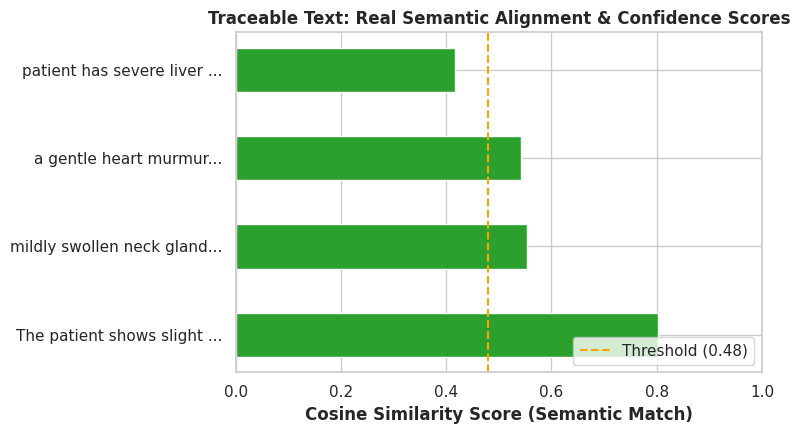

Real semantic alignment evaluation plot saved as traceable_text_alignment_benchmark.png.


In [8]:
# [CELL 4 - Quantitative Alignment Performance Metrics]

def compute_retrieval_metrics(results: List[Dict[str, Any]]) -> Dict[str, float]:
    y_true_indices = [res["true_idx"] if res["true_idx"] is not None else -999 for res in results]
    y_pred_indices = [res["predicted_idx"] if res["predicted_idx"] is not None else -999 for res in results]

    # Exact match retrieval accuracy for supported claims
    supported_mask = [t != -999 for t in y_true_indices]
    if any(supported_mask):
        correct_retrievals = sum(1 for t, p in zip(y_true_indices, y_pred_indices) if t == p and t != -999)
        total_supported = sum(1 for t in y_true_indices if t != -999)
        retrieval_accuracy = correct_retrievals / total_supported
    else:
        retrieval_accuracy = 0.0

    # Hallucination detection accuracy (correctly flagging unsupported claims)
    hallucination_correct = sum(1 for t, p in zip(y_true_indices, y_pred_indices) if t == -999 and p == -999)
    total_hallucinations = sum(1 for t in y_true_indices if t == -999)
    hallucination_detection_acc = (hallucination_correct / total_hallucinations) if total_hallucinations > 0 else 1.0

    metrics = {
        "Retrieval Accuracy (Supported Claims)": retrieval_accuracy,
        "Hallucination Detection Accuracy": hallucination_detection_acc
    }
    return metrics

metrics = compute_retrieval_metrics(eval_results)
print("\n=========================================================")
print("TRACEABLE TEXT QUANTITATIVE ALIGNMENT EVALUATION")
print("=========================================================")
for metric_name, val in metrics.items():
    print(f" -> {metric_name}: {val * 100:.1f}%")
print("=========================================================")

# Visualization of Similarity Scores vs Threshold
plt.figure(figsize=(8, 4.5))
sns.set_theme(style="whitegrid")

phrases = [res["phrase"][:25] + "..." for res in eval_results]
scores = [res["score"] for res in eval_results]
colors = ['#2ca02c' if res["predicted_idx"] == res["true_idx"] else '#d62728' for res in eval_results]

bars = plt.barh(phrases, scores, color=colors, height=0.5)
plt.axvline(x=engine.threshold, color='orange', linestyle='--', label=f'Threshold ({engine.threshold})')
plt.xlabel('Cosine Similarity Score (Semantic Match)', fontweight='bold')
plt.title('Traceable Text: Real Semantic Alignment & Confidence Scores', fontweight='bold')
plt.xlim(0.0, 1.0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig("traceable_text_alignment_benchmark.png", dpi=300)
plt.show()

print("Real semantic alignment evaluation plot saved as traceable_text_alignment_benchmark.png.")